In [1]:
import sys
sys.path.append("..")
import pandas as pd
import os

base = "/workspaces/kedaibuku-A223106-copy/data/lake/bronze/"

books = pd.read_csv(os.path.join(base, "books.csv"))
customers = pd.read_csv(os.path.join(base, "customers.csv"))
orders = pd.read_csv(os.path.join(base, "orders.csv"))
reviews = pd.read_csv(os.path.join(base, "reviews.csv"))

print(f"books: {books.shape}")
print(f"customers: {customers.shape}")
print(f"orders: {orders.shape}")
print(f"reviews: {reviews.shape}")


books: (1000, 8)
customers: (515, 7)
orders: (3060, 5)
reviews: (1200, 6)


In [2]:
# ========= 缺失值统计 =========
print("===== 缺失值统计 =====")
for name, df in [("books",books),("customers",customers),("orders",orders),("reviews",reviews)]:
    print(f"\n【{name}】")
    miss = df.isna().sum()
    print(miss[miss>0])

# ========= 重复行统计 =========
print("\n===== 完全重复行统计 =====")
print(f"books 重复行数：{books.duplicated().sum()}")
print(f"customers 重复行数：{customers.duplicated().sum()}")
print(f"orders 重复行数：{orders.duplicated().sum()}")
print(f"reviews 重复行数：{reviews.duplicated().sum()}")



===== 缺失值统计 =====

【books】
Series([], dtype: int64)

【customers】
email    25
dtype: int64

【orders】
Series([], dtype: int64)

【reviews】
review_text    50
dtype: int64

===== 完全重复行统计 =====
books 重复行数：0
customers 重复行数：15
orders 重复行数：60
reviews 重复行数：0


In [6]:
# -------- customers 业务异常检查 --------
print("==== customers 业务脏数据 ====")
empty_email = customers["email"].isna() | (customers["email"].str.strip() == "")
print(f"客户邮箱为空记录数：{empty_email.sum()}")

empty_phone = customers["phone"].isna() | (customers["phone"].str.strip() == "")
print(f"客户手机号为空记录数：{empty_phone.sum()}")


# -------- orders 业务异常检查 --------
print("\n==== orders 业务脏数据 ====")
# 这里用 quantity（数量），而不是 total_amount
invalid_qty = orders["quantity"] <= 0
print(f"订单数量 <= 0 的行数：{invalid_qty.sum()}")

custid_null = orders["customer_id"].isna()
print(f"orders customer_id 为空：{custid_null.sum()}")

bookid_null = orders["book_id"].isna()
print(f"orders book_id 为空：{bookid_null.sum()}")


# -------- books 检查价格异常 --------
print("\n==== books 业务脏数据 ====")
print("books 的列：", books.columns.tolist())
# 如果 books 里面价格字段名字是 price 才可以跑下面这句
if "price" in books.columns:
    zero_price = books["price"] <= 0
    print(f"书本价格 <= 0：{zero_price.sum()}")


==== customers 业务脏数据 ====
客户邮箱为空记录数：25
客户手机号为空记录数：0

==== orders 业务脏数据 ====
订单数量 <= 0 的行数：27
orders customer_id 为空：0
orders book_id 为空：0

==== books 业务脏数据 ====
books 的列： ['book_id', 'title', 'category', 'price_raw', 'rating_raw', 'availability', 'url', 'ingested_at']


In [ ]:
print("==== books 业务脏数据 ====")
zero_price = books["price_raw"] <= 0
print(f"书本 price_raw <= 0：{zero_price.sum()}")


orders 的全部列名：
['order_id', 'customer_id', 'book_id', 'quantity', 'order_date']

customers 的全部列名：
['customer_id', 'full_name', 'email', 'phone', 'mykad', 'state', 'signup_date']


In [7]:
print("===== 缺失值统计 =====")
for name, df in [("books",books),("customers",customers),("orders",orders),("reviews",reviews)]:
    print(f"\n【{name}】")
    miss = df.isna().sum()
    print(miss[miss>0])

print("\n===== 完全重复行统计 =====")
print(f"books 重复行数：{books.duplicated().sum()}")
print(f"customers 重复行数：{customers.duplicated().sum()}")
print(f"orders 重复行数：{orders.duplicated().sum()}")
print(f"reviews 重复行数：{reviews.duplicated().sum()}")



===== 缺失值统计 =====

【books】
Series([], dtype: int64)

【customers】
email    25
dtype: int64

【orders】
Series([], dtype: int64)

【reviews】
review_text    50
dtype: int64

===== 完全重复行统计 =====
books 重复行数：0
customers 重复行数：15
orders 重复行数：60
reviews 重复行数：0


In [9]:
print("==== books price_raw 异常 ====")
# 转为数值，不能转的变成 NaN
books["price_num"] = pd.to_numeric(books["price_raw"], errors="coerce")
zero_price = books["price_num"] <= 0
print(f"price_raw <= 0 的行数：{zero_price.sum()}")

print("\n==== 重复行汇总 ====")
print(f"books 重复：{books.duplicated().sum()}")
print(f"customers 重复：{customers.duplicated().sum()}")
print(f"orders 重复：{orders.duplicated().sum()}")
print(f"reviews 重复：{reviews.duplicated().sum()}")


==== books price_raw 异常 ====
price_raw <= 0 的行数：0

==== 重复行汇总 ====
books 重复：0
customers 重复：15
orders 重复：60
reviews 重复：0


In [10]:
import sys
sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

B = "../data/lake/bronze"

books = pd.read_csv(f"{B}/books.csv")
customers = pd.read_csv(f"{B}/customers.csv")
orders = pd.read_csv(f"{B}/orders.csv")
reviews = pd.read_csv(f"{B}/reviews.csv")

print(len(books), len(customers), len(orders), len(reviews))


1000 515 3060 1200


In [11]:
def profile(df):
    return pd.DataFrame({
        "count": df.count(),          # 填充非空单元格数量
        "null_pct": (df.isna().mean() * 100).round(1), #空值百分比
        "distinct_count": df.nunique(), #不同唯一值数量
        "dtype": df.dtypes,         #字段数据类型
        "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })

#四张表全部运行profile
print("==== books profile ====")
display(profile(books))
print("==== customers profile ====")
display(profile(customers))
print("==== orders profile ====")
display(profile(orders))
print("==== reviews profile ====")
display(profile(reviews))


==== books profile ====


,count,null_pct,distinct_count,dtype,example
book_id,1000,0.0,1000,object,its-only-the-himalayas_981
title,1000,0.0,999,object,It's Only the Himalayas
category,1000,0.0,50,object,Travel
price_raw,1000,0.0,903,object,£45.17
rating_raw,1000,0.0,5,object,Two
availability,1000,0.0,1,object,In stock
url,1000,0.0,1000,object,https://books.toscrape.com/catalogue/its-only-...
ingested_at,1000,0.0,1,object,2026-11-25T06:17:25.889344+00:00


==== customers profile ====


,count,null_pct,distinct_count,dtype,example
customer_id,515,0.0,500,object,C0444
full_name,515,0.0,89,object,Tan Wei Ming
email,490,4.9,464,object,lim.mei.ling9@yahoo.com
phone,515,0.0,500,object,019-5180561
mykad,515,0.0,500,object,720822-01-2540
state,515,0.0,22,object,johor
signup_date,515,0.0,356,object,2025-12-02


==== orders profile ====


,count,null_pct,distinct_count,dtype,example
order_id,3060,0.0,3000,object,O00001
customer_id,3060,0.0,525,object,C0415
book_id,3060,0.0,953,object,what-if-serious-scientific-answers-to-absurd-h...
quantity,3060,0.0,5,int64,1
order_date,3060,0.0,311,object,2026-03-03


==== reviews profile ====


,count,null_pct,distinct_count,dtype,example
review_id,1200,0.0,1200,object,R00001
customer_id,1200,0.0,457,object,C0498
book_id,1200,0.0,698,object,10-happier-how-i-tamed-the-voice-in-my-head-re...
stars,1200,0.0,5,int64,2
review_text,1150,4.2,225,object,Pages were bent and the box was crushed. Overp...
review_date,1200,0.0,240,object,2026-03-03


In [12]:
checks = {
    "orders: duplicate order_id": orders["order_id"].duplicated().sum(),
    "orders: unknown customer_id": (~orders["customer_id"].isin(customers["customer_id"])).sum(),
    "orders: unknown book_id": (~orders["book_id"].isin(books["book_id"])).sum(),
    "orders: date not YYYY‑MM‑DD": pd.to_datetime(orders["order_date"], format="%Y‑%m‑%d", errors="coerce").isna().sum(),
    "orders: quantity <= 0": (orders["quantity"] <=0).sum(),
    "customers: duplicate full rows": customers.duplicated().sum(),
    "customers: missing email": customers["email"].isna().sum(),
    "reviews: phone number in text": reviews["review_text"].str.contains(r"01\d‑?\d{7}|\+601", na=False).sum(),
}

check_df = pd.Series(checks).to_frame(name="issue_count")
display(check_df)


,issue_count
orders: duplicate order_id,60
orders: unknown customer_id,28
orders: unknown book_id,0
orders: date not YYYY‑MM‑DD,3060
orders: quantity <= 0,27
customers: duplicate full rows,15
customers: missing email,25
reviews: phone number in text,7


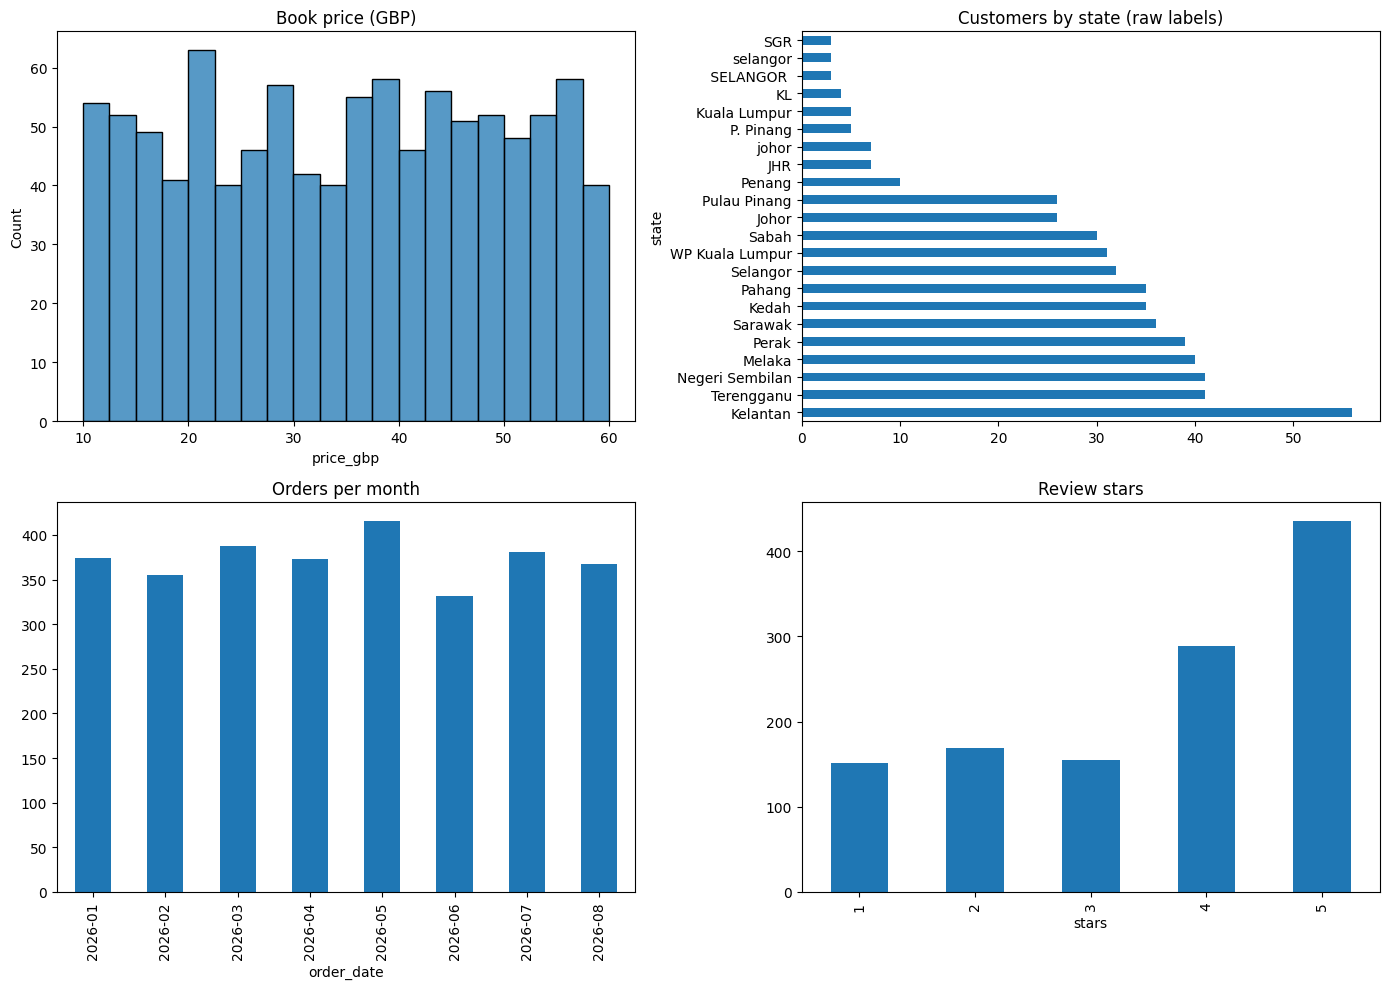

In [13]:
#清洗价格：去除£符号转数字，仅用于画图，不改动bronze原始数据
books["price_gbp"] = books["price_raw"].str.replace(r"[^0-9.]","", regex=True).astype(float)

orders_ok = orders.assign(
    order_date=pd.to_datetime(orders["order_date"], format="%Y-%m-%d", errors="coerce")
)

fig, axes = plt.subplots(2,2, figsize=(14,10))

#图1：书本价格分布
sns.histplot(books["price_gbp"], bins=20, ax=axes[0,0]).set_title("Book price (GBP)")

#图2：customers state分布（会看到state不一致拼写问题 SGR / Selangor）
customers["state"].value_counts().plot.barh(ax=axes[0,1], title="Customers by state (raw labels)")

#图3：每月订单数
orders_ok.groupby(orders_ok["order_date"].dt.to_period("M")).size().plot.bar(
    ax=axes[1,0], title="Orders per month"
)

#图4：review星星评分分布
reviews["stars"].value_counts().sort_index().plot.bar(ax=axes[1,1], title="Review stars")

plt.tight_layout()
plt.show()


In [14]:
# Data Quality Report

| Dimension | Table.column | Check | Issues found | Fix planned for Lab 5 |
| --- | --- | --- | --- | --- |
| Uniqueness | customers | duplicate rows |  | drop exact duplicates |
| Completeness | customers.email | missing values |  | keep rows; flag quality issue |
| Validity | orders.quantity | quantity ≤ 0 |  | move to quarantine |
| Consistency | customers.state | several labels per state |  | normalise state labels |
| Validity | orders.order_date | mixed date formats |  |  |
| Integrity | orders.customer_id | unknown customer |  | quarantine bad order |
| Integrity | orders.book_id | unknown book |  | quarantine bad order |
| Completeness | reviews.review_text | missing review text |  | keep row, flag |
| Privacy | reviews.review_text | phone number inside free‑text |  | mask/remove phone numbers |

## Personal data (PDPA 2010)
>【这里写段落：哪些列属于PII，MyKad是最敏感；个人信息还藏在review_text自由文本里面】

## Bias risk
>【这里写段落：review stars偏向高分，如果用这个做书籍推广会带来什么偏差；哪些state客户数量很少】



SyntaxError: invalid character '≤' (U+2264) (3131430003.py, line 7)